# SEM plane waves · incidence through an injection band

A plane P or SV wave from below, or a Rayleigh wave along the surface, in place of the
sources: SPECFEM2D's `initialfield`, on `ElasticSEM2DDeformed` and
`ViscoElasticSEM2DDeformed` (`impl='eager'`).

| `PlaneWave` | the wave |
|---|---|
| `("P", a)`, `("SV", a)` | a plane wave `a` degrees from the vertical, towards +x for `a > 0` |
| `("SV", a)` past the critical angle | its reflected P wave evanescent, bound to the surface |
| `("Rayleigh", 90)`, `("Rayleigh", -90)` | a Rayleigh wave along the surface, towards +x or -x |
| any, under an absorbing top | the whole-space wave, without the surface's reflections |

The wave enters through a band of elements one element thick around a box (the domain
reduction method). Inside the box the run carries the whole field: the plane wave of the
background and what the medium in the box scatters. From the band out it carries only the
scattered field, which the C-PML absorbs. SPECFEM2D starts its run with the plane wave in the
mesh instead and feeds it through its Stacey edges, which reflect more than the C-PML does.
Inside the box the medium is free (a topography, a basin, attenuation); outside it the
background is uniform and elastic, with a flat surface.

See [Plane-wave incidence](../user-guide/sem.md#plane-wave-incidence).

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from sweep.propagator import EagerOptions, Full
from sweep.sem import ElasticSEM2DDeformed, PlaneWave, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"   # plane waves run on impl='eager'
F64 = torch.float64
VP, VS, RHO = 2000.0, 1000.0, 2000.0     # the background rock
F0, DH, NO, DT = 4.0, 10.0, 4, 5e-4      # Ricker f0 (Hz), grid (m), GLL order, step (s)
NX, PML = 401, 40                        # 4 km wide; the C-PML, 10 elements
BOX = ((40, 0), (360, 160))              # the box: 3.2 km wide, from the surface to 1.6 km
print(f"device {DEV}")


def ricker(nt, delay):
    t = np.arange(nt) * DT - delay
    a = (np.pi * F0 * t) ** 2
    return torch.from_numpy((1.0 - 2.0 * a) * np.exp(-a))


def solver(nz=201, **kw):
    return PropSEM(ElasticSEM2DDeformed, shape=(nz, NX), dh=DH, dt=DT, n_order=NO, abcn=PML,
                   free_surface=True, f_dominant=F0, dev=DEV, dtype=F64, impl="eager",
                   memory=Full(), eager_options=EagerOptions(use_compile=False),
                   receiver_type=["u_x", "u_z"], **kw)


def rock(nz=201):
    return [torch.full((nz, NX), v, dtype=F64) for v in (VP, VS, RHO)]


def show(ax, snap, title, clip, box=True):
    """A snapshot on the grid of the model and its C-PML (no pad above the free top): the
    box dashed, the outer edge of its band dotted (``box=False``: the box's sides only)."""
    nz, nx = snap.shape
    ax.imshow(snap, cmap="seismic", vmin=-clip, vmax=clip, aspect="equal",
              extent=[-PML * DH, (nx - PML) * DH, nz * DH, 0.0])
    (x0, z0), (x1, z1) = BOX
    if box:
        ax.add_patch(Rectangle((x0 * DH, z0 * DH), (x1 - x0) * DH, (z1 - z0) * DH,
                               fill=False, ls="--", lw=0.8, ec="k"))
        ax.add_patch(Rectangle(((x0 - NO) * DH, 0.0), (x1 - x0 + 2 * NO) * DH, (z1 + NO) * DH,
                               fill=False, ls=":", lw=0.8, ec="k"))
    else:
        for x in (x0, x1):
            ax.axvline(x * DH, ls="--", lw=0.8, color="k")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("x (m)")


surf = torch.stack([torch.arange(60.0, 341.0, 20.0), torch.zeros(15)], 1).to(F64)  # (x, z) rows

device cuda


## 1. A plane SV wave in the flat half-space

The box (dashed) runs 3.2 km across and 1.6 km down from the surface; its band is the ring of
elements around it (out to the dotted line), and a 400 m margin separates the band from the
C-PML. An SV wave at 25 degrees enters through the band from the lower left. Inside the box
the run carries it, with the surface's reflected SV wave and the P wave it converts to; outside,
nothing, for nothing scatters in a flat half-space. `free_field` gives the plane wave alone at
any points, on the records' times. The wavelet is the incident displacement where the wave
first reaches the band (`origin`'s default), so a wavelet that starts at rest starts the run
at rest.

8000 steps in 21 s
surface records against the plane wave: largest difference 6.9e-04 of its peak
outside the band (in the margin): largest |u_z| 3.9e-04, 5.6e-04 of the largest inside the box (0.70)


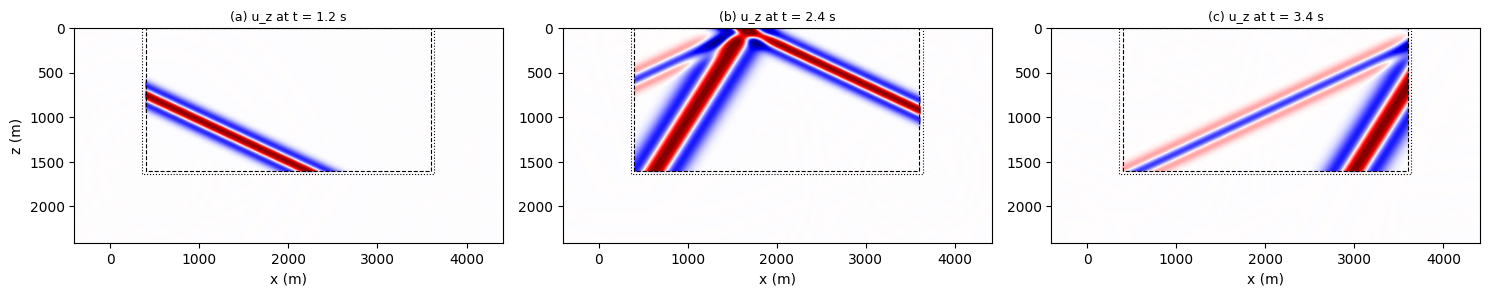

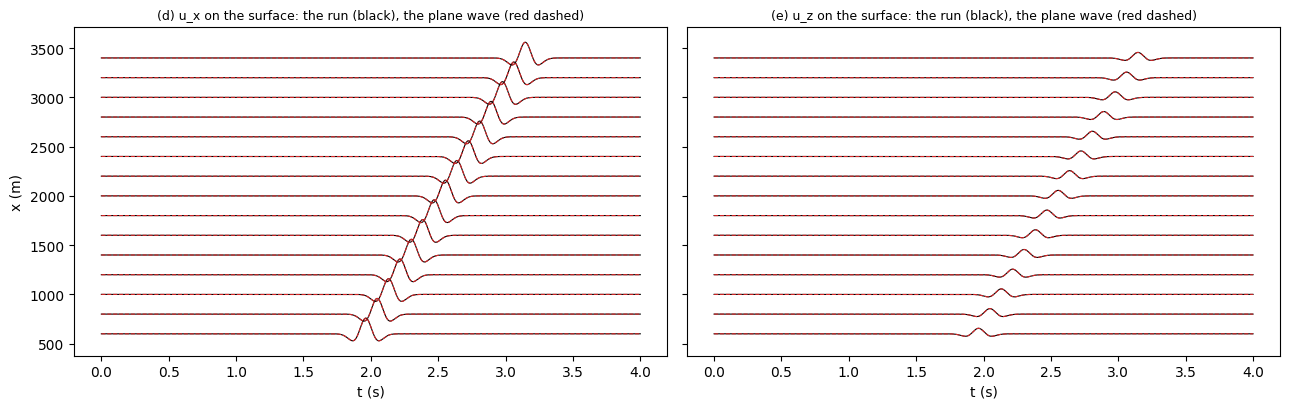

a vertical SV wave: the surface's u_x peaks at 2.0001 times the incident wave's


In [2]:
prop = solver()
NT = 8000
w = ricker(NT, 1.5 / F0)
wave = PlaneWave("SV", 25.0, box=BOX)
steps = [2400, 4800, 6800]
t0 = time.time()
seis, snaps = prop(w, wave, surf[None], models=rock(), return_wavefield=True,
                   snapshot_times=steps)
print(f"{NT} steps in {time.time() - t0:.0f} s")
seis = seis.cpu()
free = prop.free_field(w, wave, surf, rock()).cpu()    # (nrec, nt, 2), z down
err = float((seis[0] - free.transpose(0, 1)).abs().max() / free.abs().max())
print(f"surface records against the plane wave: largest difference {err:.1e} of its peak")

uz = snaps[:, 1, 0, 0].numpy()                          # u_z at the three steps
clip = float(np.percentile(np.abs(uz), 99.8))
inside = np.zeros(uz.shape[1:], bool)
inside[:BOX[1][1] + 1, PML + BOX[0][0]:PML + BOX[1][0] + 1] = True
margin = np.zeros_like(inside)
margin[:201, PML:-PML] = True                           # the model, less the box and band
margin[:BOX[1][1] + NO + 1, PML + BOX[0][0] - NO:PML + BOX[1][0] + NO + 1] = False
big, out = np.abs(uz[:, inside]).max(), np.abs(uz[:, margin]).max()
print(f"outside the band (in the margin): largest |u_z| {out:.1e}, {out / big:.1e} of the "
      f"largest inside the box ({big:.2f})")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for a, k, letter in zip(ax, range(3), "abc"):
    show(a, uz[k], f"({letter}) u_z at t = {steps[k] * DT:.1f} s", clip)
ax[0].set_ylabel("z (m)")
plt.tight_layout(); plt.show()

t = (np.arange(NT) + 1) * DT
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, c, name, letter in zip(ax, (0, 1), ("u_x", "u_z"), "de"):
    for i, x in enumerate(surf[:, 0].numpy() * DH):
        a.plot(t, x + 80.0 * seis[0, :, i, c].numpy(), "k", lw=0.8)
        a.plot(t, x + 80.0 * free[i, :, c].numpy(), "--", color="C3", lw=0.8)
    a.set_title(f"({letter}) {name} on the surface: the run (black), the plane wave "
                "(red dashed)", fontsize=9)
    a.set_xlabel("t (s)")
ax[0].set_ylabel("x (m)")
plt.tight_layout(); plt.show()

v = solver()(w, PlaneWave("SV", 0.0, box=BOX), surf[None], models=rock()).cpu()
print(f"a vertical SV wave: the surface's u_x peaks at {float(v[0, :, :, 0].abs().max()):.4f} "
      "times the incident wave's")

The surface records follow the plane wave to 7e-4 of its peak. That is the run's own error,
the leapfrog's in time: at twice the step it is 2.6e-3. In the margin outside the band the field
stays at the same level, about 6e-4 of the field inside, and a vertical SV wave doubles at the
free surface.

## 2. Past the critical angle, and a Rayleigh wave

In this rock (vp = 2 vs) an SV wave's critical angle is 30 degrees. At 40 degrees its reflected
P wave cannot propagate. It is evanescent: a P motion bound to the surface that runs with the SV
wave's footprint and decays with depth, faster at higher frequency. A Rayleigh wave is two such
waves, P and S, travelling along the surface (at 932 m/s here). One traction-free solve in the
frequency domain gives both. Their vertical motion carries the wavelet's Hilbert transform,
whose tails run ahead of the pulse: their wavelets start later, so that the run starts before
the tails reach the band (a wave already on the band at the first step is refused).

SV at 40 degrees: surface records against the plane wave, largest difference 8.0e-04 of its peak


Rayleigh: surface records against the plane wave, largest difference 1.9e-03 of its peak


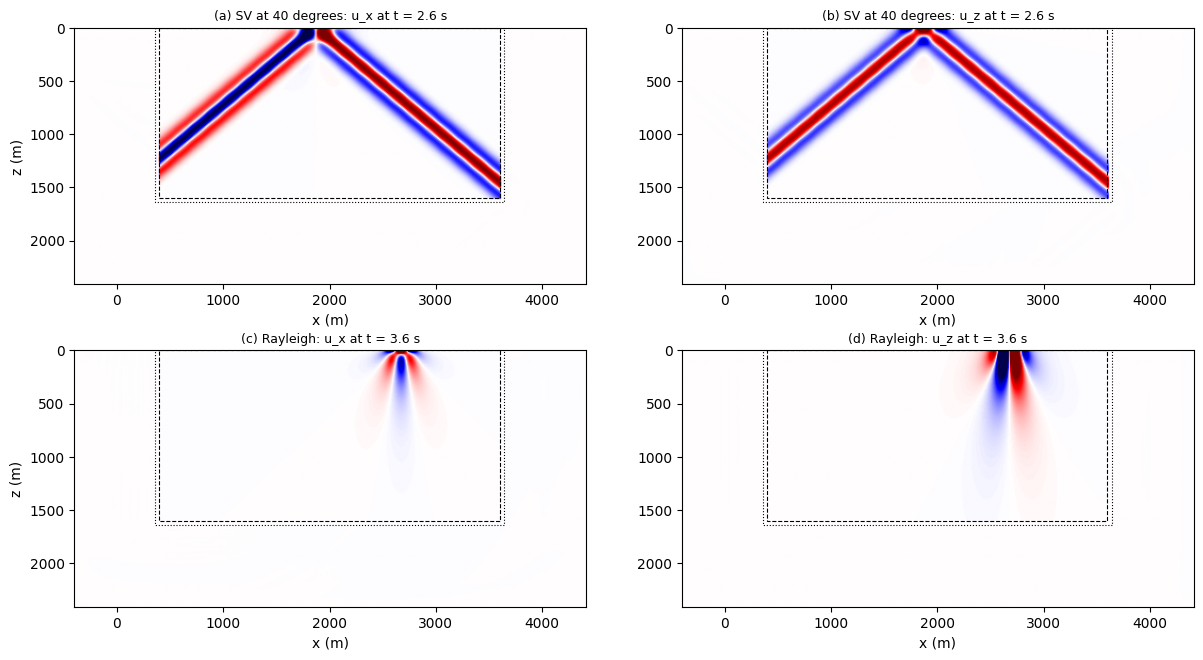

In [3]:
runs = {}
for name, wv, delay, nt, step in (
        ("SV at 40 degrees", PlaneWave("SV", 40.0, box=BOX), 1.5, 8000, 5200),
        ("Rayleigh", PlaneWave("Rayleigh", 90.0, box=BOX), 4.5, 10000, 7200)):
    p = solver()
    wn = ricker(nt, delay / F0)
    s, snap = p(wn, wv, surf[None], models=rock(), return_wavefield=True,
                snapshot_times=[step])
    s, f = s.cpu(), p.free_field(wn, wv, surf, rock()).cpu()
    err = float((s[0] - f.transpose(0, 1)).abs().max() / f.abs().max())
    print(f"{name}: surface records against the plane wave, largest difference {err:.1e} "
          "of its peak")
    runs[name] = (snap[0, :, 0, 0].numpy(), step)

fig, ax = plt.subplots(2, 2, figsize=(12.5, 6.6))
for row, (name, (snap, step)), letters in zip(ax, runs.items(), ("ab", "cd")):
    for a, c, comp, letter in zip(row, (0, 1), ("u_x", "u_z"), letters):
        show(a, snap[c], f"({letter}) {name}: {comp} at t = {step * DT:.1f} s",
             float(np.percentile(np.abs(snap), 99.8)))
for a in ax[:, 0]:
    a.set_ylabel("z (m)")
plt.tight_layout(); plt.show()

At 40 degrees (a, b) only the incident and the reflected SV waves propagate; the P motion
they make where they meet the surface is evanescent and stays near it. The Rayleigh wave
(c, d) moves the surface 1.6 times as much vertically as horizontally in this rock. With depth
its horizontal motion changes sign, at 0.17 wavelengths, and its vertical motion does not; the
lower frequencies, with the longer wavelengths, reach deeper. Its records follow the plane
wave to 2e-3 of the peak, the error of the longest path here.

## 3. A hill and a canyon

The box holds the relief of the surface; outside it the surface is flat and the medium the
background, as the plane wave's half-space is. A vertical SV wave meets a 200 m Gaussian hill
and a 200 m canyon (sigma 300 m) in the middle of the box. Under a topography the mesh's
element rows follow the surface, and `box` counts them from the top (the snapshots mark the
box's sides only). The waves the relief scatters leave the box through the band, and the
C-PML takes them.

flat: peak |u_x| on the surface 2.00 at x = 3150 m, 2.00 at its smallest


hill: peak |u_x| on the surface 2.53 at x = 2000 m, 1.93 at its smallest


canyon: peak |u_x| on the surface 2.28 at x = 2550 m, 1.89 at its smallest


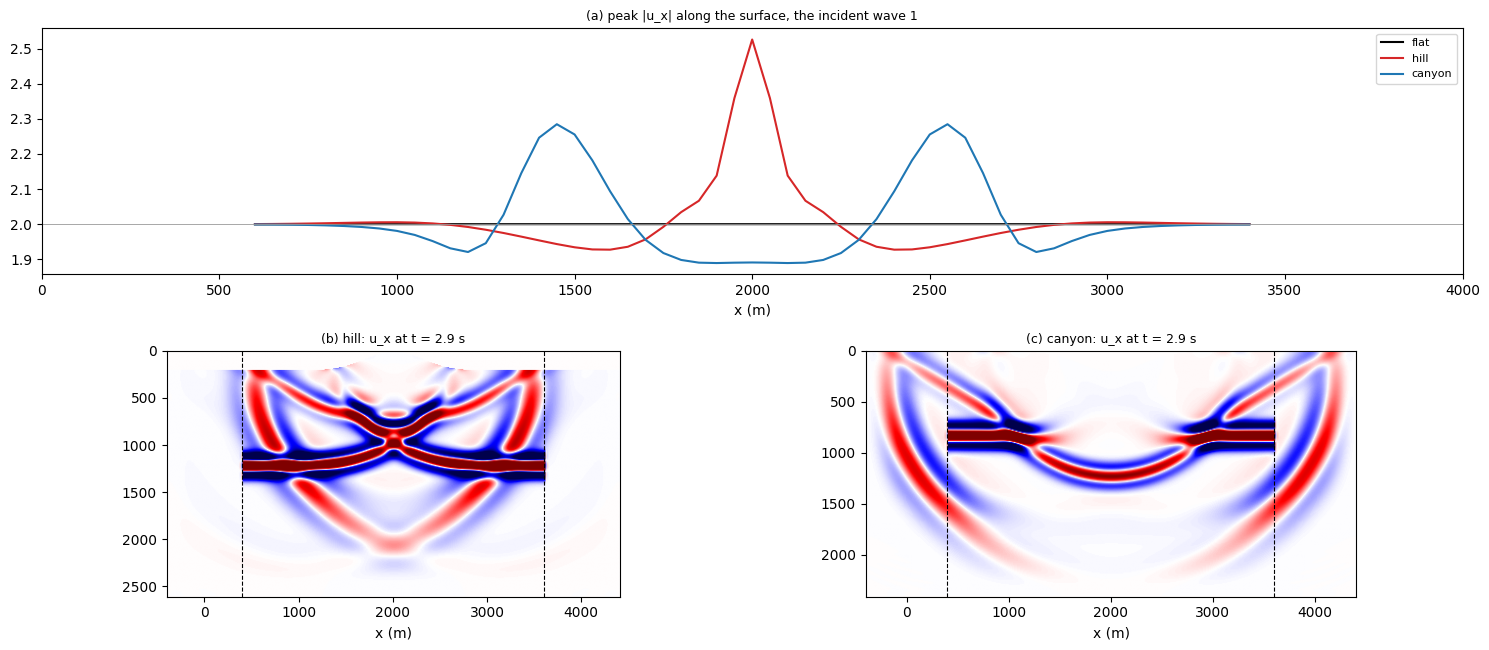

In [4]:
x = np.arange(NX) * DH
bump = 20.0 * np.exp(-0.5 * ((x - 2000.0) / 300.0) ** 2)        # 200 m, in grid rows
cases = {"flat": (None, 201), "hill": (20.0 - bump, 221), "canyon": (bump, 201)}
NT3 = 7200
w3 = ricker(NT3, 1.5 / F0)
xs = np.arange(60.0, 341.0, 5.0)                                # every 50 m
pgd, snap3 = {}, {}
for name, (topo, nz) in cases.items():
    p = solver(nz, topography=None if topo is None else torch.from_numpy(topo))
    rows = np.zeros_like(xs) if topo is None else np.interp(xs, np.arange(NX), topo)
    rec = torch.from_numpy(np.stack([xs, rows], 1))[None]
    s, snap = p(w3, PlaneWave("SV", 0.0, box=BOX), rec, models=rock(nz),
                return_wavefield=True, snapshot_times=[5800])
    pgd[name] = s[0, :, :, 0].abs().amax(0).cpu().numpy()
    snap3[name] = snap[0, 0, 0, 0].numpy()                     # u_x
    print(f"{name}: peak |u_x| on the surface {pgd[name].max():.2f} at x = "
          f"{xs[pgd[name].argmax()] * DH:.0f} m, {pgd[name].min():.2f} at its smallest")

fig = plt.figure(figsize=(15, 6.6))
a = fig.add_subplot(2, 1, 1)
for name, c in zip(cases, ("k", "C3", "C0")):
    a.plot(xs * DH, pgd[name], color=c, label=name)
a.axhline(2.0, color="0.6", lw=0.6)
a.set_xlim(0.0, NX * DH - DH)
a.set_title("(a) peak |u_x| along the surface, the incident wave 1", fontsize=9)
a.set_xlabel("x (m)"); a.legend(fontsize=8)
for k, name in enumerate(("hill", "canyon")):
    b = fig.add_subplot(2, 2, 3 + k)
    show(b, snap3[name], f"({'bc'[k]}) {name}: u_x at t = {5800 * DT:.1f} s",
         0.25 * float(np.abs(snap3[name]).max()), box=False)
plt.tight_layout(); plt.show()

On the summit the motion is 2.53 times the incident wave's (1.27 times the flat surface's 2)
and on its flanks 1.93; the canyon's floor drops to 1.89 and its rims rise to 2.28. The
colour scale of (b) and (c) clips at a quarter of the peak to show the scattered waves. Inside
the box they ride on the plane wave, here on its way back down after the surface reflected
it; outside it, in the margin and the C-PML, they are all there is.

## 4. A soft basin

A basin of soft sediment (vs 500 m/s, vp 1200 m/s, rho 1800 kg/m3), 1.2 km wide and 200 m
deep, in the box under the same vertical SV wave: its waves are trapped between the surface
and the rock below, and the shaking over it is larger and lasts longer. The basin may also
attenuate (`ViscoElasticSEM2DDeformed`, Q finite inside the box only).

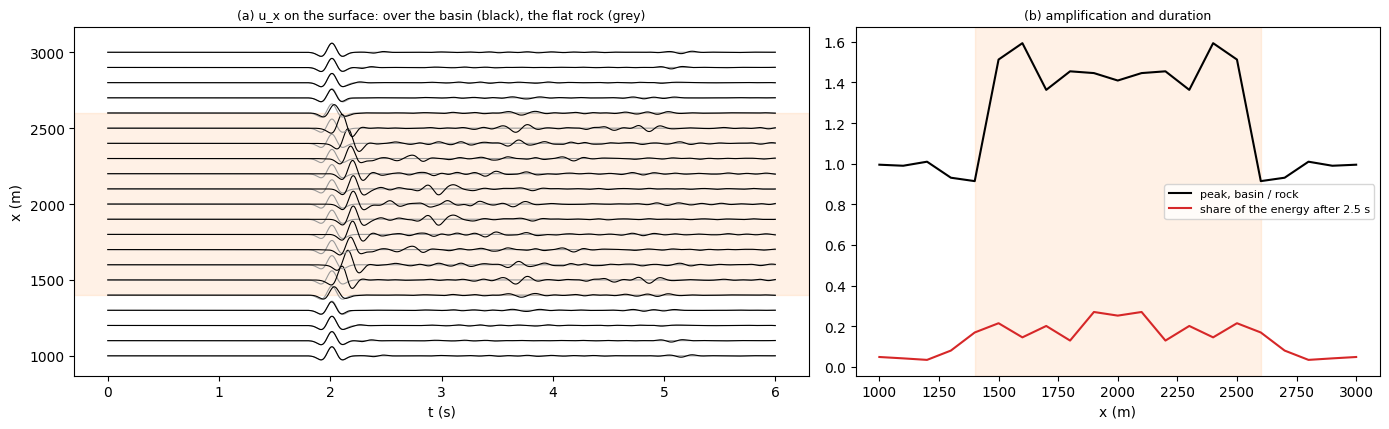

over the basin the peak is up to 1.59 times the rock's, and 0.13 to 0.27 of the energy comes after 2.5 s (0.08 at most beside it)


In [5]:
vp, vs, rho = rock()
X, Z = np.meshgrid(np.arange(NX) * DH, np.arange(201) * DH)
basin = torch.from_numpy(((X - 2000.0) / 600.0) ** 2 + (Z / 200.0) ** 2 < 1.0)
vp[basin], vs[basin], rho[basin] = 1200.0, 500.0, 1800.0
NT4 = 12000
w4 = ricker(NT4, 1.5 / F0)
rec4 = torch.stack([torch.arange(100.0, 301.0, 10.0), torch.zeros(21)], 1).to(F64)
flat = solver()(w4, PlaneWave("SV", 0.0, box=BOX), rec4[None], models=rock())[0].cpu()
soft = solver()(w4, PlaneWave("SV", 0.0, box=BOX), rec4[None], models=[vp, vs, rho])[0].cpu()

t = (np.arange(NT4) + 1) * DT
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
for i, xr in enumerate(rec4[:, 0].numpy() * DH):
    ax[0].plot(t, xr + 30.0 * flat[:, i, 0].numpy(), color="0.6", lw=0.8)
    ax[0].plot(t, xr + 30.0 * soft[:, i, 0].numpy(), "k", lw=0.8)
ax[0].axhspan(1400.0, 2600.0, color="C1", alpha=0.1)
ax[0].set_title("(a) u_x on the surface: over the basin (black), the flat rock (grey)",
                fontsize=9)
ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("x (m)")
peak_f, peak_s = flat[..., 0].abs().amax(0).numpy(), soft[..., 0].abs().amax(0).numpy()
late = (t > 2.5)[:, None]
dur = (soft[..., 0].numpy() ** 2 * late).sum(0) / (soft[..., 0].numpy() ** 2).sum(0)
ax[1].plot(rec4[:, 0].numpy() * DH, peak_s / peak_f, "k", label="peak, basin / rock")
ax[1].plot(rec4[:, 0].numpy() * DH, dur, "C3", label="share of the energy after 2.5 s")
ax[1].axvspan(1400.0, 2600.0, color="C1", alpha=0.1)
ax[1].set_title("(b) amplification and duration", fontsize=9)
ax[1].set_xlabel("x (m)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
over = ((rec4[:, 0] * DH >= 1400.0) & (rec4[:, 0] * DH <= 2600.0)).numpy()
print(f"over the basin the peak is up to {(peak_s / peak_f).max():.2f} times the rock's, and "
      f"{dur[over].min():.2f} to {dur[over].max():.2f} of the energy comes after 2.5 s "
      f"({dur[~over].max():.2f} at most beside it)")

Over the basin the waves the soft sediment traps between the surface and the rock below
reverberate long after the direct pulse has passed, and its edges send surface waves out over
the rock beside it.

## 5. Against SPECFEM2D

`test/sem/specfem_compare/run_compare_planewave.py` runs these waves against SPECFEM2D 8.1.0's
`initialfield` (double precision; the rock vp 2, vs 1, rho 1, elements of 0.1, f0 = 1, the
cases of `make_specfem_planewave_cases.py`):

| Case (domain) | ours vs the plane wave | SPECFEM2D vs the plane wave | ours vs SPECFEM2D |
|---|---|---|---|
| P at 30° (8 x 4) | 2.0e-4 | 2.9e-3 | 3.0e-3 |
| SV at 20° (8 x 4) | 3.7e-4 | 2.3e-3 | 2.3e-3 |
| SV at 40°, past the critical angle (8 x 4) | 4.2e-4 | 2.0e-3 | 2.0e-3 |
| Rayleigh (8 x 4) | 4.0e-4 | 2.5e-3 | 2.7e-3 |
| SH at 30° (8 x 4) | 3.9e-4 | 1.0e-1 | 1.0e-1 |
| P at 20° in a whole space (8 x 4) | 1.6e-4 | 4.7e-3 | 4.8e-3 |
| P at 30° (24 x 12) | 2.4e-4 | 2.5e-4 | 1.3e-4 |
| SV at 20° (24 x 12) | 4.6e-4 | 2.4e-4 | 2.4e-4 |
| SH at 30° (24 x 12) | 4.8e-4 | 2.7e-4 | 2.3e-4 |
| SV at 20° under a soft basin (24 x 12) | | | 2.5e-4 |

(relative L2 over every receiver and component)

SPECFEM2D starts with the exact plane wave in its mesh, while ours is the one the mesh carried
in from the band, so the two differ by each run's own error. In the small domain SPECFEM2D's
Stacey edges, 1 to 3 from the receivers, add 2e-3 to 5e-3 of their own; in the large one,
whose edges are far, the two runs meet each other to 1.3e-4 to 2.5e-4. In SH its Stacey edges
do not feed the incident wave in, and its records near them miss the plane wave by up to 20%
of the peak. Its frequency-domain field (past the critical angle, the Rayleigh wave) is
`-0.5` times the wavelet (fitted -0.50007 and -0.50028), and its SH wave `cos(a)` times it
(0.866027 at 30 degrees).